# Module 6: Fashion MNIST Classification with a 6-Layer CNN
Builds a CNN as a Python class, trains it on Fashion MNIST, predicts sample images,
and saves the model for the FastAPI service.

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

# Same order as CLASS_NAMES in fashion-mnist-service/main.py (label 0 ... 9)
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
SERVICE_FOLDER = "fashion-mnist-service"

## 2. Load and prepare the data

In [8]:
# Load and scale in ONE cell so re-running never divides twice
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())   

X_train: (60000, 28, 28, 1) | y_train: (60000,)
X_test:  (10000, 28, 28, 1) | y_test:  (10000,)
Pixel range: 0.0 to 1.0


## 3. The CNN class

In [9]:
class FashionCNN:
    """A six-layer convolutional neural network for Fashion MNIST."""

    def __init__(self):
        # Six layers: Conv2D, MaxPooling2D, Conv2D, MaxPooling2D, Flatten, Dense
        self.model = keras.Sequential([
            keras.Input(shape=(28, 28, 1)),                  
            layers.Conv2D(32, (3, 3), activation="relu"),  
            layers.MaxPooling2D((2, 2)),                     
            layers.Conv2D(64, (3, 3), activation="relu"),   
            layers.MaxPooling2D((2, 2)),                     
            layers.Flatten(),                                
            layers.Dense(10, activation="softmax"),          
        ])
        self.model.compile(optimizer="adam",
                           loss="sparse_categorical_crossentropy",
                           metrics=["accuracy"])

    def train(self, x, y, epochs=5):
        """Train on the training data, holding back 10% to check for overfitting."""
        return self.model.fit(x, y, epochs=epochs, batch_size=64, validation_split=0.1)

    def evaluate(self, x, y):
        """Return [loss, accuracy] on unseen data."""
        return self.model.evaluate(x, y, verbose=0)

    def predict(self, images):
        """Return the predicted class index and confidence for each image."""
        probabilities = self.model.predict(images, verbose=0)
        return probabilities.argmax(axis=1), probabilities.max(axis=1)

    def save(self, path):
        """Save the trained model to a .keras file."""
        self.model.save(path)

## 4. Train and evaluate

In [10]:
cnn = FashionCNN()
cnn.model.summary()  

history = cnn.train(X_train, y_train, epochs=5)

test_loss, test_accuracy = cnn.evaluate(X_test, y_test)
print(f"\nTest accuracy: {test_accuracy * 100:.2f}%")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 19ms/step - accuracy: 0.8067 - loss: 0.5397 - val_accuracy: 0.8473 - val_loss: 0.4271
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8726 - loss: 0.3568 - val_accuracy: 0.8743 - val_loss: 0.3483
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.8869 - loss: 0.3170 - val_accuracy: 0.8823 - val_loss: 0.3182
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8969 - loss: 0.2886 - val_accuracy: 0.8888 - val_loss: 0.3066
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9046 - loss: 0.2647 - val_accuracy: 0.8985 - val_loss: 0.2802

Test accuracy: 89.85%


## 5. Predict sample images

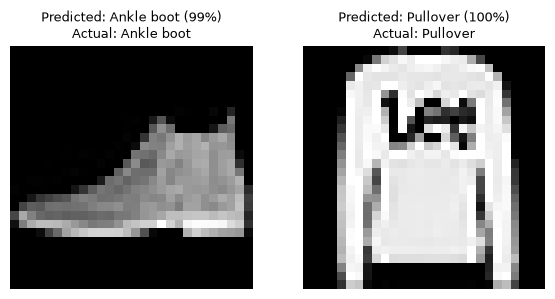

In [11]:
sample_images = X_test[:2]
predicted, confidence = cnn.predict(sample_images)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for i, ax in enumerate(axes):
    ax.imshow(sample_images[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Predicted: {CLASS_NAMES[predicted[i]]} ({confidence[i] * 100:.0f}%)\n"
                 f"Actual: {CLASS_NAMES[y_test[i]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Save the model and sample images for the API

In [12]:
# Savin the model straight into the service folder
model_path = os.path.join(SERVICE_FOLDER, "fashion_cnn.keras")
cnn.save(model_path)
print("Model saved to", model_path)

# Saving 2 test images as PNG files to send to the API
for i in range(2):
    pixels = (X_test[i].reshape(28, 28) * 255).astype("uint8")   
    label = CLASS_NAMES[y_test[i]].replace("/", "-")              
    file_name = os.path.join(SERVICE_FOLDER, f"sample_{i}_{label}.png")
    Image.fromarray(pixels).save(file_name)
    print("Saved", file_name)

Model saved to fashion-mnist-service\fashion_cnn.keras
Saved fashion-mnist-service\sample_0_Ankle boot.png
Saved fashion-mnist-service\sample_1_Pullover.png


## 7. Results
- Architecture: 6 layers (Conv2D, MaxPooling2D, Conv2D, MaxPooling2D, Flatten, Dense).
- Python test accuracy: 89.64% on 10,000 unseen images (R version: 88.64%).
- Both sample predictions were correct: Ankle boot and Pullover.
- The model is saved as fashion-mnist-service/fashion_cnn.keras for the FastAPI service.